# Default of Credit Card Clients (UCI)

The objective is to predict the probability a customer will default next month, and identify key risk drivers to support underwriting decisions.

### 1. Importing Libraries

In [6]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# ML tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve

# Models
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

### 2. Load and Explore Dataset

In [7]:
df = pd.read_csv("UCI_Credit_Card.csv")
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [8]:
df.shape

(30000, 25)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [10]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [11]:
df.dtypes

ID                              int64
LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_AMT1                     float64
BILL_AMT2                     float64
BILL_AMT3                     float64
BILL_AMT4                     float64
BILL_AMT5                     float64
BILL_AMT6                     float64
PAY_AMT1                      float64
PAY_AMT2                      float64
PAY_AMT3                      float64
PAY_AMT4                      float64
PAY_AMT5                      float64
PAY_AMT6                      float64
default.payment.next.month      int64
dtype: object

In [12]:
df.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='str')

### 3. Target Variable Distribution

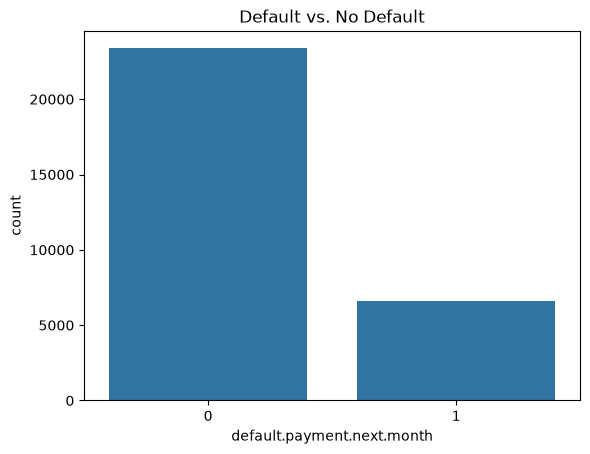

In [15]:
sns.countplot(x='default.payment.next.month', data=df)
plt.title("Default vs. No Default")
plt.show()

The dataset is imbalanced — there are more non-default customers than defaulting customers, which is typical in credit card lending.
Banks must identify the smaller risky group early to reduce losses.

### 4. Select Features & Split Data

In [16]:
X = df.drop(['ID', 'default.payment.next.month'], axis=1)
y = df['default.payment.next.month']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y) #Stratify keeps target balance consistent.

### 5. Scaling Numeric Inputs

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 6. Model 1 - Logistic Regression

Logistic Regression Model is used because it is widely used in banking, it is highly explanable and it is easy to implement in policy.

In [19]:
log_model = LogisticRegression(max_iter=2000)
log_model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [20]:
log_pred = log_model.predict(X_test_scaled)
log_acc = accuracy_score(y_test, log_pred)
log_auc = roc_auc_score(y_test, log_model.predict_proba(X_test_scaled)[:,1])

In [21]:
print("Logistic Regression Accuracy:", log_acc)
print("Logistic Regression AUC:", log_auc)
print("Classification Report:", classification_report(y_test, log_pred))

Logistic Regression Accuracy: 0.8096
Logistic Regression AUC: 0.7155275850834744
Classification Report:               precision    recall  f1-score   support

           0       0.82      0.97      0.89      5841
           1       0.70      0.24      0.36      1659

    accuracy                           0.81      7500
   macro avg       0.76      0.61      0.62      7500
weighted avg       0.79      0.81      0.77      7500



In [22]:
#Confusion Matrix

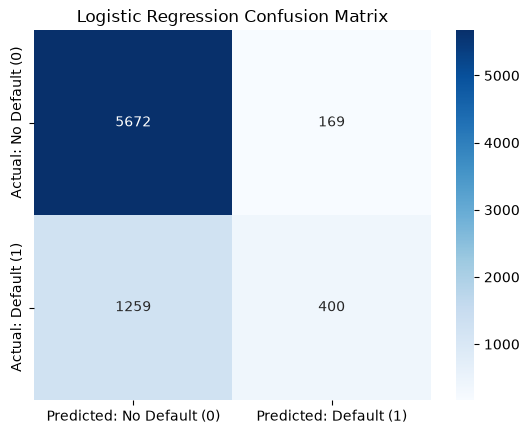

In [23]:
cm = confusion_matrix(y_test, log_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Predicted: No Default (0)", "Predicted: Default (1)"],
            yticklabels=["Actual: No Default (0)", "Actual: Default (1)"])
plt.title("Logistic Regression Confusion Matrix")
plt.show()

### Model 2. - XGBoost 

Better predictive power, Captures nonlinear patterns, Used in credit scoring systems,

In [24]:
xgb_model = XGBClassifier(
    eval_metric='logloss',
    learning_rate=0.1,
    n_estimators=200,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8)

xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [25]:
xgb_pred = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1])

In [26]:
print("XGBoost Accuracy:", xgb_acc)
print("XGBoost AUC:", xgb_auc)
print("Classification Report:", classification_report(y_test, xgb_pred))

XGBoost Accuracy: 0.8190666666666667
XGBoost AUC: 0.7772292865620478
Classification Report:               precision    recall  f1-score   support

           0       0.84      0.95      0.89      5841
           1       0.67      0.36      0.47      1659

    accuracy                           0.82      7500
   macro avg       0.75      0.66      0.68      7500
weighted avg       0.80      0.82      0.80      7500



### 7. Model Comparison

In [27]:
print("Logistic Regression: AUC =", log_auc)
print("XGBoost: AUC =", xgb_auc)

Logistic Regression: AUC = 0.7155275850834744
XGBoost: AUC = 0.7772292865620478


Credit risk patterns are non-linear. XGBoost models complex interactions between features (like payment delay + bill amount trends), unlike Logistic Regression which assumes a straight-line relationship. That’s why XGBoost detects defaulters more accurately.
XGBoost demonstrates superior discriminatory power, increasing AUC by ~6%, which reduces false approvals of high-risk customers.

### 8. Feature Importance (Risk Drivers)

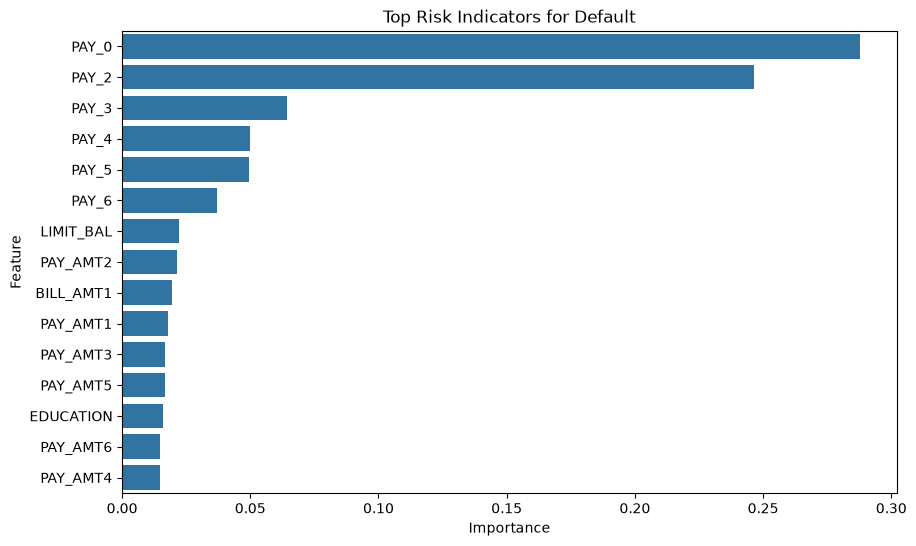

,Feature,Importance
5,PAY_0,0.287860
6,PAY_2,0.246290
7,PAY_3,0.064240
8,PAY_4,0.049994
9,PAY_5,0.049615
10,PAY_6,0.036887
0,LIMIT_BAL,0.022025
18,PAY_AMT2,0.021259
11,BILL_AMT1,0.019338
17,PAY_AMT1,0.017866


In [28]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=importance.head(15), x='Importance', y='Feature')
plt.title("Top Risk Indicators for Default")
plt.show()

importance.head(10)

Payment delay history is the strongest predictor of credit default. Customers who recently failed to pay on time are significantly more likely to default next month.

### 9. Behavioral Trend Analysis of Credit Risk

In [29]:
# Group data by default status and calculate mean for each month feature
trend_pay = df.groupby('default.payment.next.month')[['PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']].mean()
trend_bill = df.groupby('default.payment.next.month')[['BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6']].mean()
trend_payment = df.groupby('default.payment.next.month')[['PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']].mean()

# For better labeling
month_labels = ['Sep','Aug','Jul','Jun','May','Apr']

#### Plot 1 — Delinquency Trend (PAY Variables) = Shows whether payment delays are getting worse or improving

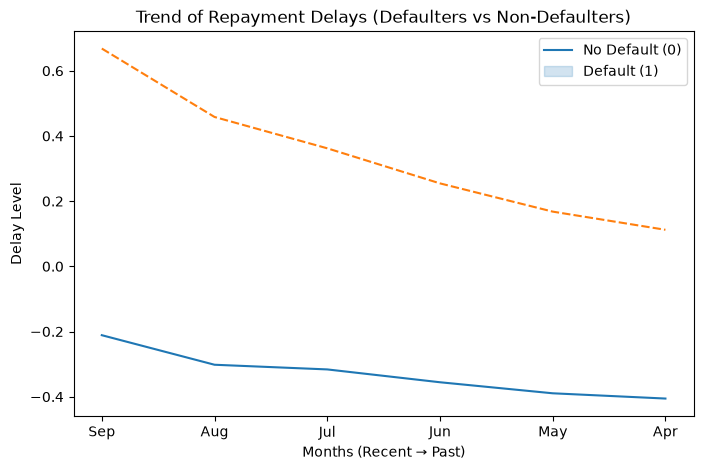

In [30]:
plt.figure(figsize=(8,5))
sns.lineplot(data=trend_pay.T)
plt.title("Trend of Repayment Delays (Defaulters vs Non-Defaulters)")
plt.xlabel("Months (Recent → Past)")
plt.ylabel("Delay Level")
plt.xticks(range(6), month_labels)
plt.legend(['No Default (0)', 'Default (1)'])
plt.show()

Defaulters show consistently higher delay values and worsening trends → strong warning signal.

#### Plot 2 — Outstanding Debt Trend (Bills Increasing) = Shows credit burden rising before default

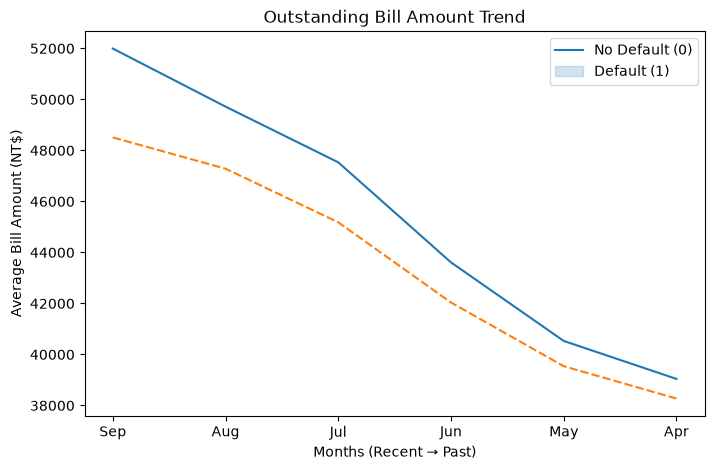

In [31]:
plt.figure(figsize=(8,5))
sns.lineplot(data=trend_bill.T)
plt.title("Outstanding Bill Amount Trend")
plt.xlabel("Months (Recent → Past)")
plt.ylabel("Average Bill Amount (NT$)")
plt.xticks(range(6), month_labels)
plt.legend(['No Default (0)', 'Default (1)'])
plt.show()

Defaulters accumulate more debt as months go by → rising financial stress.

#### Plot 3 — Payment Amount Trend (PAY_AMT) = Defaulters pay less and less → strong risk signal

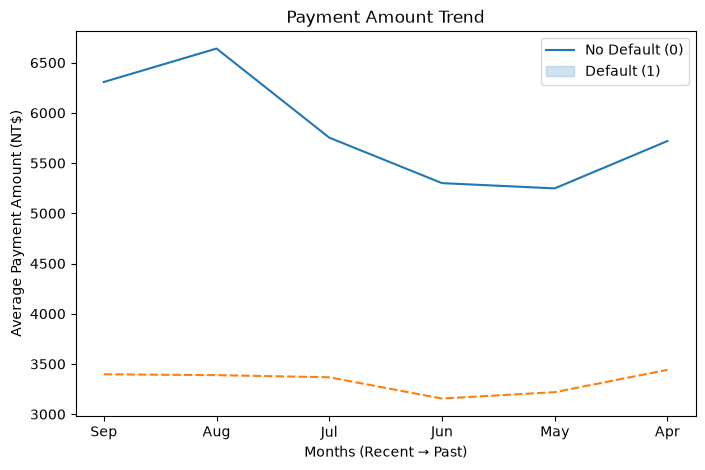

In [32]:
plt.figure(figsize=(8,5))
sns.lineplot(data=trend_payment.T)
plt.title("Payment Amount Trend")
plt.xlabel("Months (Recent → Past)")
plt.ylabel("Average Payment Amount (NT$)")
plt.xticks(range(6), month_labels)
plt.legend(['No Default (0)', 'Default (1)'])
plt.show()

Their payment amount decreases → they are unable to keep up repayments.

### 10. Business Insights

Defaulters show:
 1. Increasing delinquency (more late payments)
 2. Rising unpaid balances
 3. Declining repayment amounts
    
These behavioral changes start months before default

Banks should trigger early interventions when:
 1. Debt rises 3 months in a row
 2. Repayments drop significantly
 3. Customer has even one late payment in the recent month

This helps prevent losses & improve customer management.

Trend analysis clearly shows that credit stress builds over months — allowing banks to detect high-risk customers early and act before default occurs.

### 11. Some other measures to calculate Expected Loss based on Basel II/III Standards

In [33]:
test_df = X_test.copy()  # make a DataFrame

In [34]:
#PD = Probability of Default (predicted probability)
test_df['PD'] = xgb_model.predict_proba(X_test)[:,1]

#EAD = Exposure At Default
test_df['EAD'] = df.loc[X_test.index, 'BILL_AMT1']  

#lGD = Loss Given Default - Since UCI dataset doesn’t have actual loss data, we can assume a standard value (like 45–50% as banks often do for unsecured credit cards).Normally, it Can be estimated based on historical data.
LGD = 0.45

test_df['Expected_Loss'] = test_df['PD'] * test_df['EAD'] * LGD

In [35]:
test_df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,PD,EAD,Expected_Loss
16895,50000.0,1,2,1,45,1,2,0,0,0,...,20058.0,0.0,2065.0,1376.0,701.0,705.0,706.0,0.450328,49436.0,10018.076641
6382,80000.0,2,2,1,30,1,2,0,0,0,...,78710.0,0.0,3299.0,2699.0,3000.0,2987.0,3100.0,0.357836,82891.0,13347.629715
14305,160000.0,1,3,1,42,1,-1,-1,-2,-1,...,436.0,1564.0,0.0,0.0,872.0,0.0,0.0,0.199181,0.0,0.000000
15699,20000.0,1,2,1,31,1,4,3,2,0,...,18062.0,0.0,0.0,0.0,1000.0,1000.0,1000.0,0.464386,21676.0,4529.713206
18485,130000.0,2,2,2,26,0,0,0,2,2,...,131986.0,6000.0,12600.0,4900.0,5105.0,0.0,5050.0,0.297604,131336.0,17588.726786


In [36]:
test_df.shape

(7500, 26)

We train the model on historical customer behavior. When new customer data comes in, we apply the model to predict default probability (PD), calculate expected loss (EL), and identify the highest-risk accounts. The training data is never reused for decision-making on new customers.

In [37]:
#OPTIONAL

In [38]:
train_df = X_train.copy()  # X_train = training features

In [39]:
train_df['PD'] = xgb_model.predict_proba(X_train)[:,1]
train_df['EAD'] = df.loc[X_train.index, 'BILL_AMT1']  # use BILL_AMT1 from original df
LGD = 0.45
train_df['Expected_Loss'] = train_df['PD'] * train_df['EAD'] * LGD

In [40]:
train_df.head(10)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,PD,EAD,Expected_Loss
27350,200000.0,1,1,2,32,-1,-1,-1,-2,-2,...,0.0,2182.0,0.0,0.0,0.0,0.0,0.0,0.218759,1125.0,110.746789
22029,320000.0,2,1,2,28,0,0,0,0,0,...,20553.0,13300.0,12756.0,1295.0,10312.0,8394.0,8242.0,0.101180,293073.0,13343.956169
22166,170000.0,2,1,2,27,-1,-1,2,-1,-1,...,736.0,1536.0,0.0,736.0,736.0,736.0,736.0,0.226996,356.0,36.364750
1880,90000.0,2,3,1,40,0,0,0,0,0,...,49488.0,3416.0,4142.0,1700.0,1888.0,2710.0,1500.0,0.134908,89928.0,5459.386926
1319,250000.0,2,1,1,43,-1,-1,-1,0,0,...,5922.0,24890.0,48394.0,0.0,5461.0,15000.0,6000.0,0.062997,17454.0,494.797500
26563,50000.0,2,3,2,56,0,0,0,0,0,...,16194.0,1798.0,2058.0,1683.0,600.0,1017.0,20698.0,0.152107,48155.0,3296.119379
24679,130000.0,2,1,2,33,2,2,-2,-2,-2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.568069,1022.0,261.255007
8102,360000.0,1,1,1,48,0,0,0,0,0,...,7691.0,6206.0,10030.0,1061.0,1011.0,3016.0,189853.0,0.060319,167922.0,4557.973792
27267,160000.0,1,1,1,42,2,2,0,0,2,...,17701.0,0.0,1247.0,2145.0,0.0,2000.0,0.0,0.846440,14137.0,5384.756652
19117,20000.0,2,3,1,44,0,0,0,2,2,...,0.0,1457.0,2600.0,2000.0,0.0,0.0,0.0,0.380556,7661.0,1311.947533


### 12. Age Factor

In [41]:
# Average default rate by age
age_default = df.groupby('AGE')['default.payment.next.month'].mean()
age_default.head(10)  # shows first 10 ages

AGE
21    0.208955
22    0.301786
23    0.265306
24    0.266193
25    0.254637
26    0.201433
27    0.211916
28    0.202981
29    0.195016
30    0.196416
Name: default.payment.next.month, dtype: float64

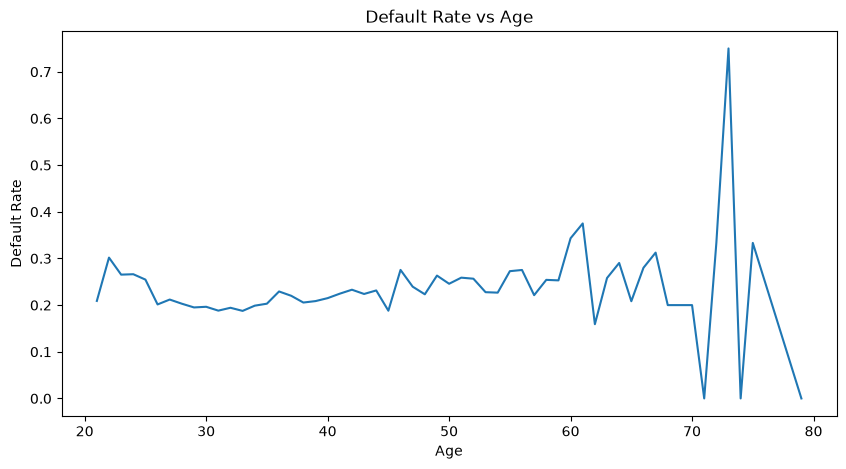

In [42]:
plt.figure(figsize=(10,5))
sns.lineplot(x=age_default.index, y=age_default.values)
plt.title("Default Rate vs Age")
plt.xlabel("Age")
plt.ylabel("Default Rate")
plt.show()

INTERPRETATION

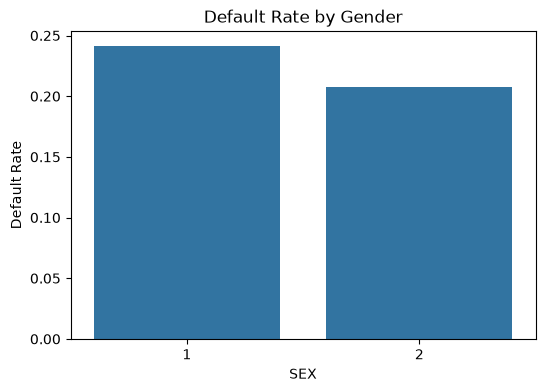

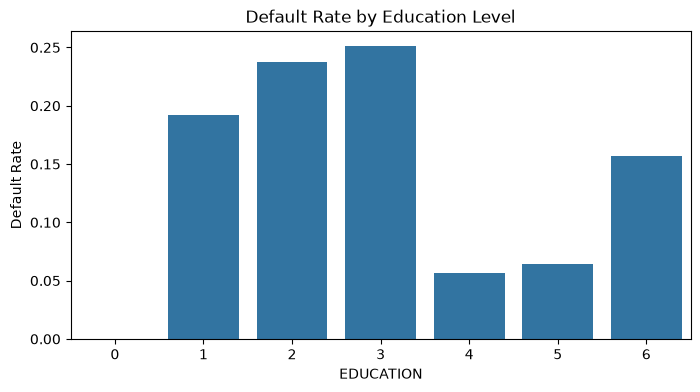

In [43]:
# Default rate by SEX
sex_default = df.groupby('SEX')['default.payment.next.month'].mean()  #1=male, 2=female
plt.figure(figsize=(6,4))
sns.barplot(x=sex_default.index, y=sex_default.values)
plt.title("Default Rate by Gender")
plt.ylabel("Default Rate")
plt.show()

# Default rate by EDUCATION
edu_default = df.groupby('EDUCATION')['default.payment.next.month'].mean()  #1=graduate school, 2=university, 3=high school, 4=others, 5=unknown, 6=unknown
plt.figure(figsize=(8,4))
sns.barplot(x=edu_default.index, y=edu_default.values)
plt.title("Default Rate by Education Level")
plt.ylabel("Default Rate")
plt.show()

In [44]:
X_test.dtypes

LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_0          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
dtype: object